In [1]:
%pip install tensorflow[cuda] mlflow pandas azure-storage-blob matplotlib datasets

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from azure.storage.blob import BlobServiceClient
import os
# set AZURE_STORAGE_CONNECTION_STRING in the environment first
service = BlobServiceClient.from_connection_string(os.environ["AZURE_STORAGE_CONNECTION_STRING"])
container = service.get_container_client("kcrowly-vast")


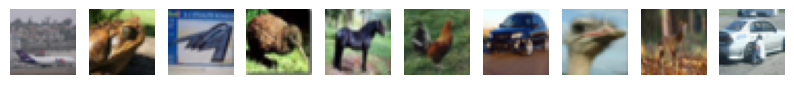

In [3]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt
ds = load_dataset("uoft-cs/cifar10")

X_train = np.stack([np.array(img) for img in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"])
X_test = np.stack([np.array(img) for img in ds["test"]["img"]])
y_test = np.array(ds["test"]["label"])
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i+1)
    plt.imshow(X_train[i])
    plt.axis('off')
plt.show()


MobileNet v2 PreProc

In [4]:
from datasets import load_dataset
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.utils import to_categorical

ds = load_dataset("uoft-cs/cifar10")

X_train = np.stack([np.array(img) for img in ds["train"]["img"]])
y_train = np.array(ds["train"]["label"]).reshape(-1, 1)
X_test = np.stack([np.array(img) for img in ds["test"]["img"]])
y_test = np.array(ds["test"]["label"]).reshape(-1, 1)

2026-10-21 11:56:56.848319: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792583816.856572    2316 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792583816.859019    2316 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792583816.866918    2316 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792583816.866934    2316 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792583816.866946    2316 computation_placer.cc:177] computation placer alr

In [5]:
import tensorflow as tf

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, tf.one_hot(label[0], 10)

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

I0000 00:00:1792583827.421910    2316 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22322 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3090, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
from tensorflow.keras.applications import MobileNetV2
base_model = MobileNetV2(weights='imagenet',
                        include_top=False,
                        input_shape=(224,224,3))
base_model.trainable = False

In [7]:
from tensorflow.keras import layers,models

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')  # 10 classes for CIFAR-10
])
model.compile(optimizer='adam',
             loss = 'categorical_crossentropy',
             metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
from tensorflow.keras.callbacks import EarlyStopping , ModelCheckpoint

early_stop = EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)
checkpoint = ModelCheckpoint('mobilenetv2_cifar10.h5',save_best_only=True)


history = model.fit(train_ds,validation_data=test_ds,epochs=10,
                   callbacks=[early_stop,checkpoint])

Epoch 1/10


I0000 00:00:1792583832.549363    2401 service.cc:152] XLA service 0x7f4208001530 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792583832.549404    2401 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 3090, Compute Capability 8.6
2026-10-21 11:57:12.660815: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792583833.148583    2401 cuda_dnn.cc:529] Loaded cuDNN version 90300
2026-10-21 11:57:14.046992: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_4391', 204 bytes spill stores, 204 bytes spill loads

2026-10-21 11:57:14.267969: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_670

  15/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.1717 - loss: 2.6576  

I0000 00:00:1792583838.109288    2401 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1558/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.6856 - loss: 0.9355 

...

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8000 - loss: 0.5965 - val_accuracy: 0.8333 - val_loss: 0.4777
Epoch 3/10
1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8145 - loss: 0.5469 

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8145 - loss: 0.5469 - val_accuracy: 0.8370 - val_loss: 0.4566
Epoch 4/10
1562/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8241 - loss: 0.5222 

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 23s 14ms/step - accuracy: 0.8241 - loss: 0.5222 - val_accuracy: 0.8456 - val_loss: 0.4534
Epoch 5/10
1560/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8301 - loss: 0.5005 

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8301 - loss: 0.5005 - val_accuracy: 0.8481 - val_loss: 0.4408
Epoch 6/10
1560/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8349 - loss: 0.4800 

1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8349 - loss: 0.4800 - val_accuracy: 0.8517 - val_loss: 0.4358
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8385 - loss: 0.4645 - val_accuracy: 0.8532 - val_loss: 0.4360
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8428 - loss: 0.4535 - val_accuracy: 0.8509 - val_loss: 0.4395
Epoch 9/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 22s 14ms/step - accuracy: 0.8472 - loss: 0.4442 - val_accuracy: 0.8487 - val_loss: 0.4418


In [9]:
with open("mobilenetv2_cifar10.h5", "rb") as f:
    container.upload_blob("models/mobilenetv2_cifar10.h5", f, overwrite=True)

In [10]:
import subprocess, time

subprocess.run(["pkill", "-f", "mlflow"])
time.sleep(3)

p = subprocess.Popen(
    ["mlflow", "server", "--host", "0.0.0.0", "--port", "5000",
     "--disable-security-middleware"],
    stdout=open("mlflow.log", "w"), stderr=subprocess.STDOUT,
)
time.sleep(15)

print("exit code:", p.poll())
print(open("mlflow.log").read()[-1500:])

exit code: None
ild_environ
/venv/main/lib/python3.10/site-packages/mlflow/server/fastapi_app.py:23: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_environ
2026/10/21 12:00:57 INFO:     Started server process [3360]
2026/10/21 12:00:57 INFO:     Waiting for application startup.
2026/10/21 12:00:57 INFO:     Application startup complete.
2026/10/21 12:00:57 INFO:     Started server process [3357]
2026/10/21 12:00:57 INFO:     Waiting for application startup.
2026/10/21 12:00:57 INFO:     Application startup complete.
2026/10/21 12:00:57 INFO:     Started server process [3358]
2026/10/21 12:00:57 INFO:     Waiting for application startup.
2026/10/21 12:00:57 INFO:     Application startup complete.
2026/10/21 12:00:57 INFO:     Started server process [3359]
2026/10/21 12:00:57 INFO:     Waiting f

In [11]:
import os
print(os.path.abspath("mobilenetv2_cifar10.h5"))


/mobilenetv2_cifar10.h5


## Fine Tuning

In [12]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.8502 - loss: 0.4423
Test Accuracy: 0.85


In [13]:
base_model.trainable = True

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='categorical_crossentropy',
              metrics = ['accuracy'])

In [14]:
fine_tune_epochs = 10
total_epochs = 10 + fine_tune_epochs

history_fine = model.fit(train_ds,
                         epochs=total_epochs,
                         initial_epoch=10,
                         validation_data=test_ds)

Epoch 11/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 110s 53ms/step - accuracy: 0.6704 - loss: 1.0734 - val_accuracy: 0.6105 - val_loss: 1.1936
Epoch 12/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.8293 - loss: 0.5258 - val_accuracy: 0.8168 - val_loss: 0.5568
Epoch 13/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.8755 - loss: 0.3813 - val_accuracy: 0.8756 - val_loss: 0.3722
Epoch 14/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.9094 - loss: 0.2793 - val_accuracy: 0.8992 - val_loss: 0.3094
Epoch 15/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.9313 - loss: 0.2105 - val_accuracy: 0.9041 - val_loss: 0.3054
Epoch 16/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.9484 - loss: 0.1570 - val_accuracy: 0.9054 - val_loss: 0.3140
Epoch 17/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy: 0.9643 - loss: 0.1153 - val_accuracy: 0.9095 - val_loss: 0.3202
Epoch 18/20
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 66s 42ms/step - accuracy:

## Evaluation :



In [15]:
loss, acc = model.evaluate(test_ds)
print(f"Test Accuracy: {acc:.2f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9115 - loss: 0.3684
Test Accuracy: 0.91
